# Time-series analysis of Pandora visits (VISDA and NIRDA)

This notebook takes every VISDA (`*_VisSci_*_l2.fits`) and NIRDA (`*_InfImg_*_l2.fits`) Level 2 file in a folder, reduces each to a light curve, groups the files into visits, removes instrumental trends over each visit, and looks at the planet's transits in both detectors and in a few NIR wavelength channels. The per-file reductions follow `01_visda_reduction.ipynb` and `02_nirda_reduction.ipynb`, which explain them in detail.

A Pandora observation of a target is a series of files, roughly one per orbit (about 95 minutes), each typically 30 to 40 minutes long, taken while the target is visible. Files close together in time form a *visit*. A transit (WASP-52b: 1.8 hours) is longer than a file, so trends must be removed over whole visits, not file by file, or the transit would be fitted away.

**Steps:**

1. **Per-file reduction.** VISDA: aperture sum, centroid, background. NIRDA: bad pixels masked and filled from the trace profile, a white light curve from the uncontaminated rows, light curves in wavelength channels, the trace's column position, background.
2. **Times** at mid-exposure, converted to BJD_TDB to match published ephemerides.
3. **Visits** are runs of files separated by less than `VISIT_GAP_HOURS`.
4. **Frame flags.** The first `SETTLE_MINUTES` of each file (pointing settle and detector ramp after a slew), frames with the target more than `MAX_OFFSET_PIXELS` from its usual position, and frames whose background is more than `BACKGROUND_SIGMA` robust standard deviations above its median in the file (scattered earthshine, typically at the end of a file).
5. **Detrending per visit.** Out of transit, the relative flux is fitted with a quadratic in time over the visit, the target's position offsets, and two exponential ramps since the start of each file; the light curve is divided by this model.
6. **Transit.** Folded light curves and a simple box depth per detector and channel.

Set `DIRECTORY` and the planet's ephemeris below. Without an ephemeris (`EPHEMERIS = None`) the notebook stops after the detrended light curves.

In [1]:
# Standard library
import warnings
from pathlib import Path

# Third-party
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.coordinates import EarthLocation
from astropy.time import Time
from scipy.ndimage import binary_dilation, median_filter

# First-party/Local
import pandorafits as pf

plt.style.use(pf.PANDORASTYLE)
warnings.simplefilter("ignore", RuntimeWarning)
pf.logger.setLevel("ERROR")

In [2]:
DIRECTORY = Path("Path", "to", "level2")

# WASP-52b. Ephemeris in BJD_TDB from Kokori et al. 2023; Rp/R* (only used
# for a reference line) from the same source.
EPHEMERIS = dict(t0=2456784.057988, period=1.74978117, duration_hours=1.81)
RP_RS = 0.1646

VISIT_GAP_HOURS = 6
SETTLE_MINUTES = 2
MAX_OFFSET_PIXELS = 1
BACKGROUND_SIGMA = 5
OUTLIER_SIGMA = 5
BIN_MINUTES = 5
# Extra time [minutes] around the predicted transit treated as in transit,
# for ephemeris uncertainty.
TRANSIT_MARGIN_MINUTES = 10
# NIRDA wavelength channels [micron].
CHANNELS = [(0.90, 1.10), (1.10, 1.30), (1.30, 1.50), (1.50, 1.65)]
# NIRDA extraction settings, as in 02_nirda_reduction.ipynb.
PROFILE_ROWS = 8
MIN_CAPTURED_FRACTION = 0.5
MIN_RELATIVE_SENSITIVITY = 0.05

## Per-file reductions

`TIME` is the start of each VISDA co-add, and for NIRDA (pandora-fits 0.9.0 and earlier) the start of the second read group of each integration. The middle of the exposure is about `TIME + EXPTIME / 2` for VISDA and `TIME - EXPTIME / 2` for NIRDA. Times are converted from JD (UTC) to BJD_TDB at the geocenter; Pandora's distance from it changes the light travel time by less than 0.03 s.

In [3]:
GEOCENTER = EarthLocation.from_geocentric(0, 0, 0, unit="m")
NEIGHBORS = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool)


def to_bjd_tdb(time_jd, coord):
    times = Time(time_jd, format="jd", scale="utc", location=GEOCENTER)
    return (times.tdb + times.light_travel_time(coord)).jd


def reduce_visda_file(path):
    # Aperture sum, centroid and background per co-add (01 notebook).
    hdulist = pf.open(path)
    header = hdulist[0].header
    background = hdulist["BACKGROUND"].data
    cube = hdulist["SCIENCE"].data - background[:, None, None]
    target = (hdulist["APERTURE"].data & 2) == 2
    row_index, column_index = np.mgrid[: cube.shape[1], : cube.shape[2]]
    weights = np.where(target, cube, 0)
    flux = weights.sum(axis=(1, 2))
    mid_jd = hdulist["TIME"].data + hdulist["EXPTIME"].data / 2 / 86400
    return pd.DataFrame(dict(
        bjd=to_bjd_tdb(mid_jd, hdulist.coord),
        file_minutes=(mid_jd - mid_jd[0]) * 1440,
        flux=flux,
        column=(weights * column_index).sum(axis=(1, 2)) / flux
        + header["ROISTRTX"],
        row=(weights * row_index).sum(axis=(1, 2)) / flux
        + header["ROISTRTY"],
        background=background,
        file=path.name,
    ))


def reduce_nirda_file(path):
    # Masked-and-filled extraction (02 notebook), summed to a white light
    # curve (uncontaminated rows) and to the wavelength channels.
    hdulist = pf.open(path)
    background = hdulist["BACKGROUND"].data
    cube = hdulist["SCIENCE"].data - background[:, :, None]
    nframes, nrows, ncols = cube.shape
    aperture_bits = hdulist["APERTURE"].data
    target = (aperture_bits & 2) == 2
    contaminated = target & ((aperture_bits & 4) == 4)
    flagged = hdulist["QUALITY"].data != 0
    masked = target & binary_dilation(flagged, NEIGHBORS)
    good = target & ~masked

    # Temporal outliers in the aperture pixels.
    pixels = cube[:, target]
    running = median_filter(pixels, size=(7, 1), mode="nearest")
    residual = pixels - running
    sigma = 1.4826 * np.median(np.abs(residual), axis=0)
    cube[:, target] = np.where(np.abs(residual) > 7 * sigma, running, pixels)

    target_rows = target.any(axis=1)
    contaminated_rows = contaminated.any(axis=1)
    clean_rows = np.where(
        target_rows & ~(masked | contaminated).any(axis=1)
    )[0]
    clean_profiles = np.where(target[clean_rows], cube[:, clean_rows], 0)
    clean_profiles /= clean_profiles.sum(axis=2, keepdims=True)
    spectra = np.full((nframes, nrows), np.nan)
    captured = np.ones((nframes, nrows))
    for row in np.where(target_rows)[0]:
        if masked[row].any():
            nearest = np.argsort(np.abs(clean_rows - row))[:PROFILE_ROWS]
            profile = np.median(clean_profiles[:, nearest], axis=1)
            profile *= target[row]
            profile /= profile.sum(axis=1, keepdims=True)
            captured[:, row] = np.where(good[row], profile, 0).sum(axis=1)
        spectra[:, row] = (
            np.where(good[row], cube[:, row], 0).sum(axis=1)
            / captured[:, row]
        )

    solution = hdulist["WAVELENGTH_SOLUTION"].data
    wavelength = solution["wavelength"]
    sensitivity = solution["sensitivity"]
    use_rows = (
        target_rows
        & (np.median(captured, axis=0) >= MIN_CAPTURED_FRACTION)
        & (sensitivity > MIN_RELATIVE_SENSITIVITY * np.nanmax(sensitivity))
        & ~contaminated_rows
    )
    trace = np.where(good, cube, 0)
    column = (
        (trace * np.arange(ncols)).sum(axis=(1, 2)) / trace.sum(axis=(1, 2))
        + hdulist[0].header["ROISTRTX"]
    )
    mid_jd = hdulist["TIME"].data - hdulist["EXPTIME"].data / 2 / 86400
    table = dict(
        bjd=to_bjd_tdb(mid_jd, hdulist.coord),
        file_minutes=(mid_jd - mid_jd[0]) * 1440,
        flux=np.nansum(spectra[:, use_rows], axis=1),
        column=column,
        # Along the dispersion the trace position is taken from the
        # pointing (VECTORS posy).
        row=hdulist["VECTORS"].data["posy"],
        background=np.median(background, axis=1),
        file=path.name,
    )
    for low, high in CHANNELS:
        in_channel = use_rows & (wavelength >= low) & (wavelength < high)
        table[f"flux_{low:.2f}-{high:.2f}"] = np.nansum(
            spectra[:, in_channel], axis=1
        )
    return pd.DataFrame(table)

In [4]:
visda_paths = sorted(DIRECTORY.glob("*_VisSci_*_l2.fits"))
nirda_paths = sorted(DIRECTORY.glob("*_InfImg_*_l2.fits"))
print(f"{len(visda_paths)} VISDA and {len(nirda_paths)} NIRDA files")

visda = pd.concat([reduce_visda_file(p) for p in visda_paths])
nirda = pd.concat([reduce_nirda_file(p) for p in nirda_paths])
channel_columns = [c for c in nirda.columns if c.startswith("flux_")]
first_header = pf.open(visda_paths[0])[0].header
target_name = first_header["TARG_ID"]
print(f"{len(visda)} VISDA co-adds and {len(nirda)} NIRDA integrations")

77 VISDA and 77 NIRDA files


17483 VISDA co-adds and 28119 NIRDA integrations


## Visits

Files separated by less than `VISIT_GAP_HOURS` belong to the same visit. Predicted transits (mid-times from the ephemeris) inside each visit are listed.

In [5]:
file_starts = (
    pd.concat([visda, nirda]).groupby("file")["bjd"].min().sort_values()
)
new_visit = np.diff(file_starts.values, prepend=-np.inf) > (
    VISIT_GAP_HOURS / 24
)
visit_of_file = pd.Series(np.cumsum(new_visit), index=file_starts.index)
for table in (visda, nirda):
    table["visit"] = table["file"].map(visit_of_file).values
    table.sort_values("bjd", inplace=True)
    table.reset_index(drop=True, inplace=True)


def nearest_transit(bjd):
    # Mid-time [BJD_TDB] of the predicted transit nearest each time.
    if EPHEMERIS is None:
        return np.full(np.shape(bjd), np.nan)
    epoch = np.round((bjd - EPHEMERIS["t0"]) / EPHEMERIS["period"])
    return EPHEMERIS["t0"] + epoch * EPHEMERIS["period"]


rows = []
for visit, files in visit_of_file.groupby(visit_of_file):
    in_visit = pd.concat([visda, nirda]).query("visit == @visit")
    start, stop = in_visit["bjd"].min(), in_visit["bjd"].max()
    mids = nearest_transit(np.array([start, stop]))
    transits = np.unique(mids[(mids >= start) & (mids <= stop)])
    rows.append(dict(
        visit=visit,
        start_utc=Time(start, format="jd", scale="tdb").utc.iso[:16],
        hours=round((stop - start) * 24, 1),
        visda_files=visda.loc[visda.visit == visit, "file"].nunique(),
        nirda_files=nirda.loc[nirda.visit == visit, "file"].nunique(),
        transits=len(transits),
    ))
pd.DataFrame(rows).set_index("visit")

,start_utc,hours,visda_files,nirda_files,transits
visit,,,,,
1,2026-08-31 17:29,0.3,1,1,0
2,2026-09-05 11:55,23.2,15,15,1
3,2026-09-09 12:36,23.2,15,15,1
4,2026-09-30 05:28,73.2,46,46,2


## Frame flags and detrending

For each visit and each light curve, frames in the first `SETTLE_MINUTES` of a file, frames with the target more than `MAX_OFFSET_PIXELS` from its median position in the visit, and frames with a background more than `BACKGROUND_SIGMA` robust standard deviations above the file's median background are flagged. The relative flux of the remaining frames *outside* the predicted transit (with `TRANSIT_MARGIN_MINUTES` on each side) is fitted with

$$f = c_0 + c_1 t + c_2 t^2 + c_3 \Delta x + c_4 \Delta y + c_5 e^{-\tau/1\,\mathrm{min}} + c_6 e^{-\tau/6\,\mathrm{min}},$$

where $t$ is the time in the visit, $\Delta x$ and $\Delta y$ the position offsets (VISDA: centroid; NIRDA: trace column and the pointing along the dispersion) and $\tau$ the time since the start of the file (the detector settles after each slew). All frames are divided by the model. Outliers are flagged against a running median of the detrended light curve, which keeps the transit's shape.

In [6]:
def detrend(table, flux_column):
    # Returns the detrended relative flux and the mask of frames kept.
    detrended = np.full(len(table), np.nan)
    keep = np.zeros(len(table), bool)
    for visit, part in table.groupby("visit"):
        index = part.index.values
        hours = (part["bjd"].values - part["bjd"].min()) * 24
        column_offset = part["column"].values - part["column"].median()
        row_offset = part["row"].values - part["row"].median()
        transit_mid = nearest_transit(part["bjd"].values)
        half_window = (
            EPHEMERIS["duration_hours"] / 2 + TRANSIT_MARGIN_MINUTES / 60
            if EPHEMERIS is not None else 0
        )
        in_transit = (
            np.abs(part["bjd"].values - transit_mid) * 24 < half_window
        )
        flux = part[flux_column].values
        background_excess = (
            part["background"]
            - part.groupby("file")["background"].transform("median")
        ).values
        background_sigma = 1.4826 * np.median(np.abs(background_excess))
        good = (
            (part["file_minutes"].values >= SETTLE_MINUTES)
            & (np.hypot(column_offset, row_offset) < MAX_OFFSET_PIXELS)
            & (background_excess < BACKGROUND_SIGMA * background_sigma)
            & np.isfinite(flux) & (flux > 0)
        )
        fit = good & ~in_transit
        if fit.sum() < 20:
            continue
        relative = flux / np.median(flux[fit])
        minutes = part["file_minutes"].values
        design = np.vstack([
            np.ones_like(hours), hours, hours**2, column_offset, row_offset,
            np.exp(-minutes / 1), np.exp(-minutes / 6),
        ]).T
        use = fit.copy()
        for _ in range(5):
            coefficients, *_ = np.linalg.lstsq(
                design[use], relative[use], rcond=None
            )
            residual = relative - design @ coefficients
            scatter = 1.4826 * np.median(np.abs(residual[use]))
            use = fit & (np.abs(residual) < OUTLIER_SIGMA * scatter)
        corrected = relative / (design @ coefficients)
        # Outliers against a running median keep the transit's shape.
        smooth = median_filter(np.where(good, corrected, 1), size=15,
                               mode="nearest")
        scatter = 1.4826 * np.median(np.abs(corrected - smooth)[good])
        detrended[index] = corrected
        keep[index] = good & (
            np.abs(corrected - smooth) < OUTLIER_SIGMA * scatter
        )
    return detrended, keep


visda["detrended"], visda["keep"] = detrend(visda, "flux")
nirda["detrended"], nirda["keep"] = detrend(nirda, "flux")
for column in channel_columns:
    nirda[column + "_detrended"], nirda[column + "_keep"] = detrend(
        nirda, column
    )
print(f"Kept {visda.keep.mean():.0%} of VISDA and {nirda.keep.mean():.0%}"
      " of NIRDA frames")

Kept 88% of VISDA and 93% of NIRDA frames


## Detrended light curves by visit

Hours are measured from the last predicted mid-transit in a visit, otherwise from the start of the visit. Gray points are single frames, black points `BIN_MINUTES` bins; shaded bands are the predicted transits.

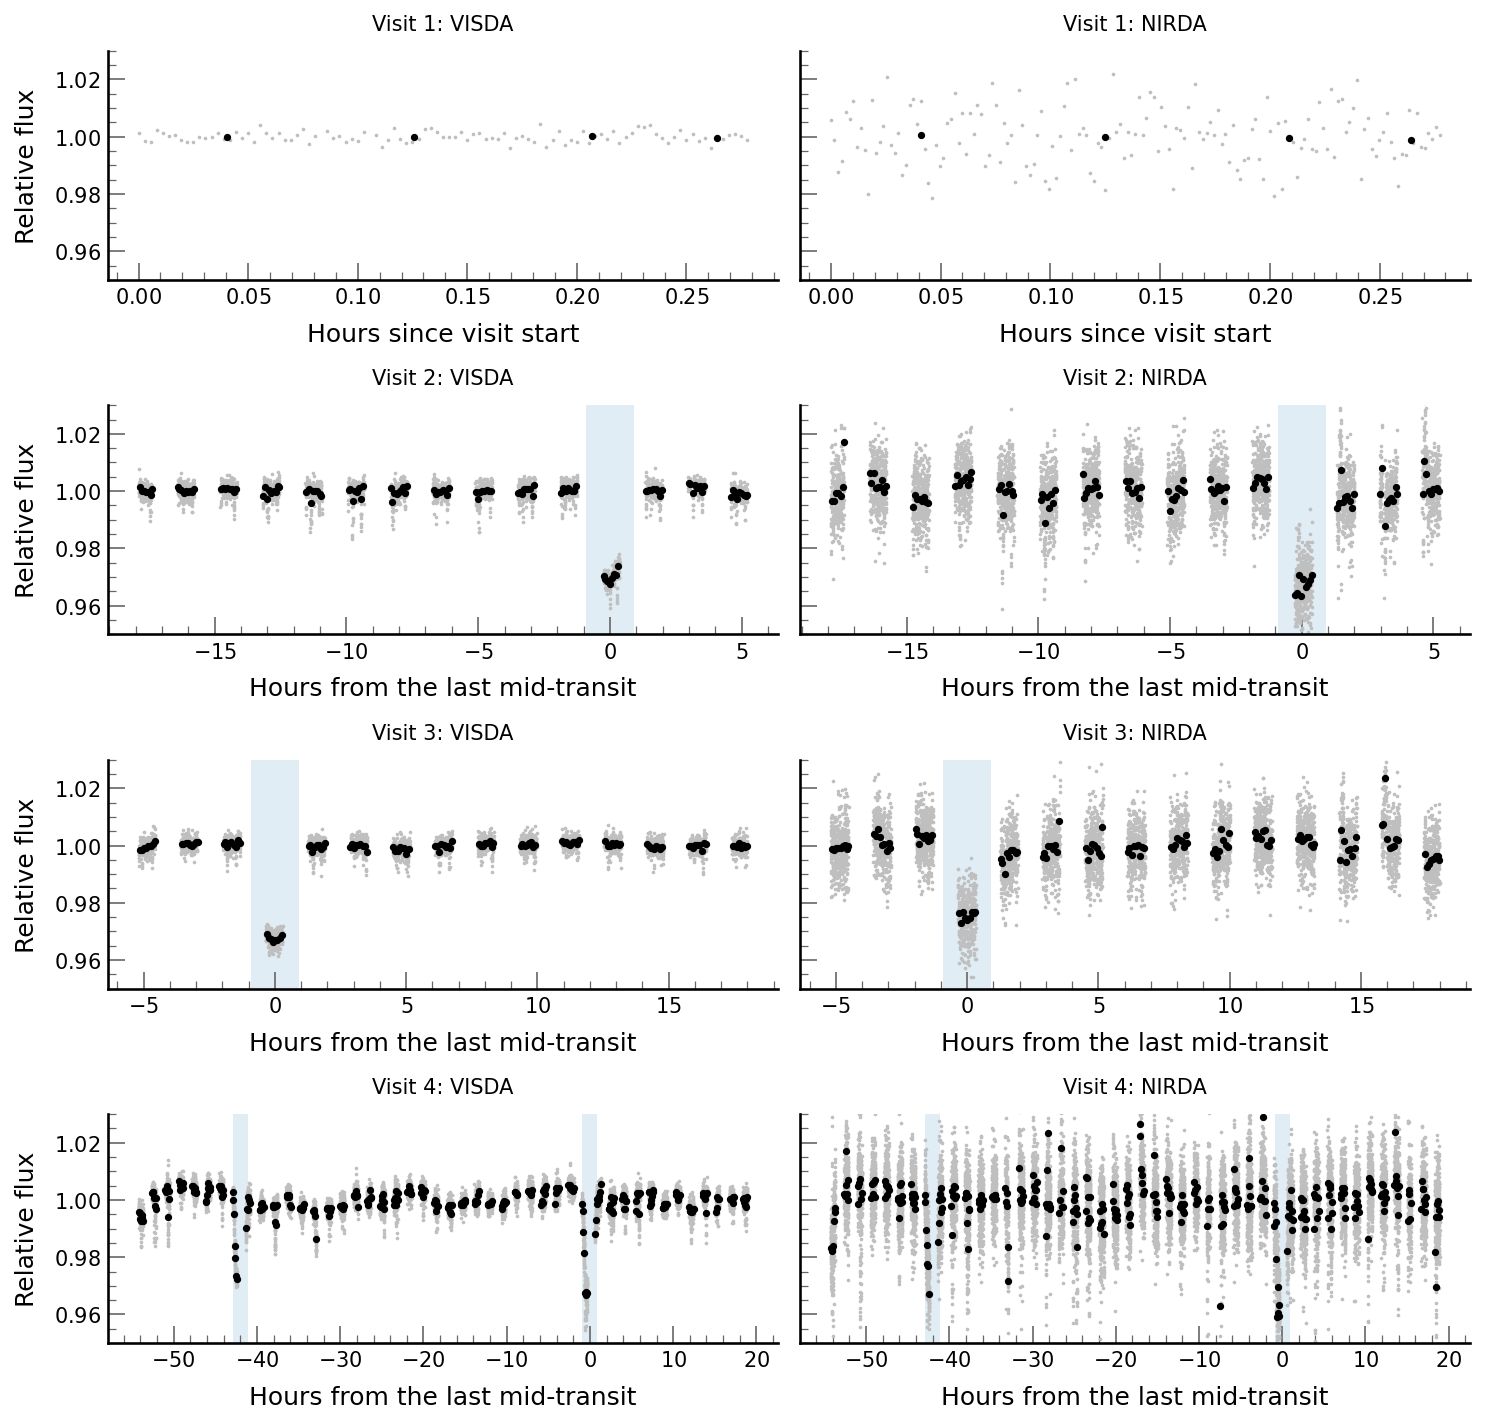

In [7]:
def visit_hours(part):
    # Hours from the last predicted mid-transit in the visit (else from the
    # visit start), and the hours of every predicted transit in the visit.
    mids = nearest_transit(part["bjd"].values)
    mids = np.unique(
        mids[(mids >= part["bjd"].min()) & (mids <= part["bjd"].max())]
    )
    reference = mids[-1] if mids.size else part["bjd"].min()
    return (
        (part["bjd"].values - reference) * 24,
        (mids - reference) * 24,
    )


def binned(x, y, width):
    edges = np.arange(x.min(), x.max() + width, width)
    which = np.digitize(x, edges)
    centers, means, errors = [], [], []
    for index in np.unique(which):
        in_bin = which == index
        if in_bin.sum() < 3:
            continue
        centers.append(x[in_bin].mean())
        means.append(y[in_bin].mean())
        errors.append(y[in_bin].std() / np.sqrt(in_bin.sum()))
    return np.array(centers), np.array(means), np.array(errors)


visits = sorted(visda["visit"].unique())
fig, axes = plt.subplots(len(visits), 2, figsize=(10, 2.4 * len(visits)),
                         sharey=True, squeeze=False)
for row_axes, visit in zip(axes, visits):
    for ax, table, name in zip(row_axes, (visda, nirda), ("VISDA", "NIRDA")):
        part = table.query("visit == @visit and keep")
        hours, transit_hours = visit_hours(part)
        ax.plot(hours, part["detrended"], ".", color="0.75", markersize=1.5)
        x, y, _ = binned(hours, part["detrended"].values, BIN_MINUTES / 60)
        ax.plot(x, y, ".", color="k", markersize=5)
        for mid in transit_hours:
            half = EPHEMERIS["duration_hours"] / 2
            ax.axvspan(mid - half, mid + half, color="#0072B2", alpha=0.12,
                       lw=0)
        ax.set_title(f"Visit {visit}: {name}", fontsize="medium")
        ax.set_xlabel("Hours from the last mid-transit" if transit_hours.size
                      else "Hours since visit start")
    row_axes[0].set_ylabel("Relative flux")
axes[0, 0].set_ylim(0.95, 1.03)
plt.show()

## Diagnostics

The background and the target's position over each visit, before flagging. Steps between files are normal (each file starts after a slew). A background that climbs at the end of a file is scattered earthshine; those frames are flagged above. Large position jumps are pointing problems, also flagged.

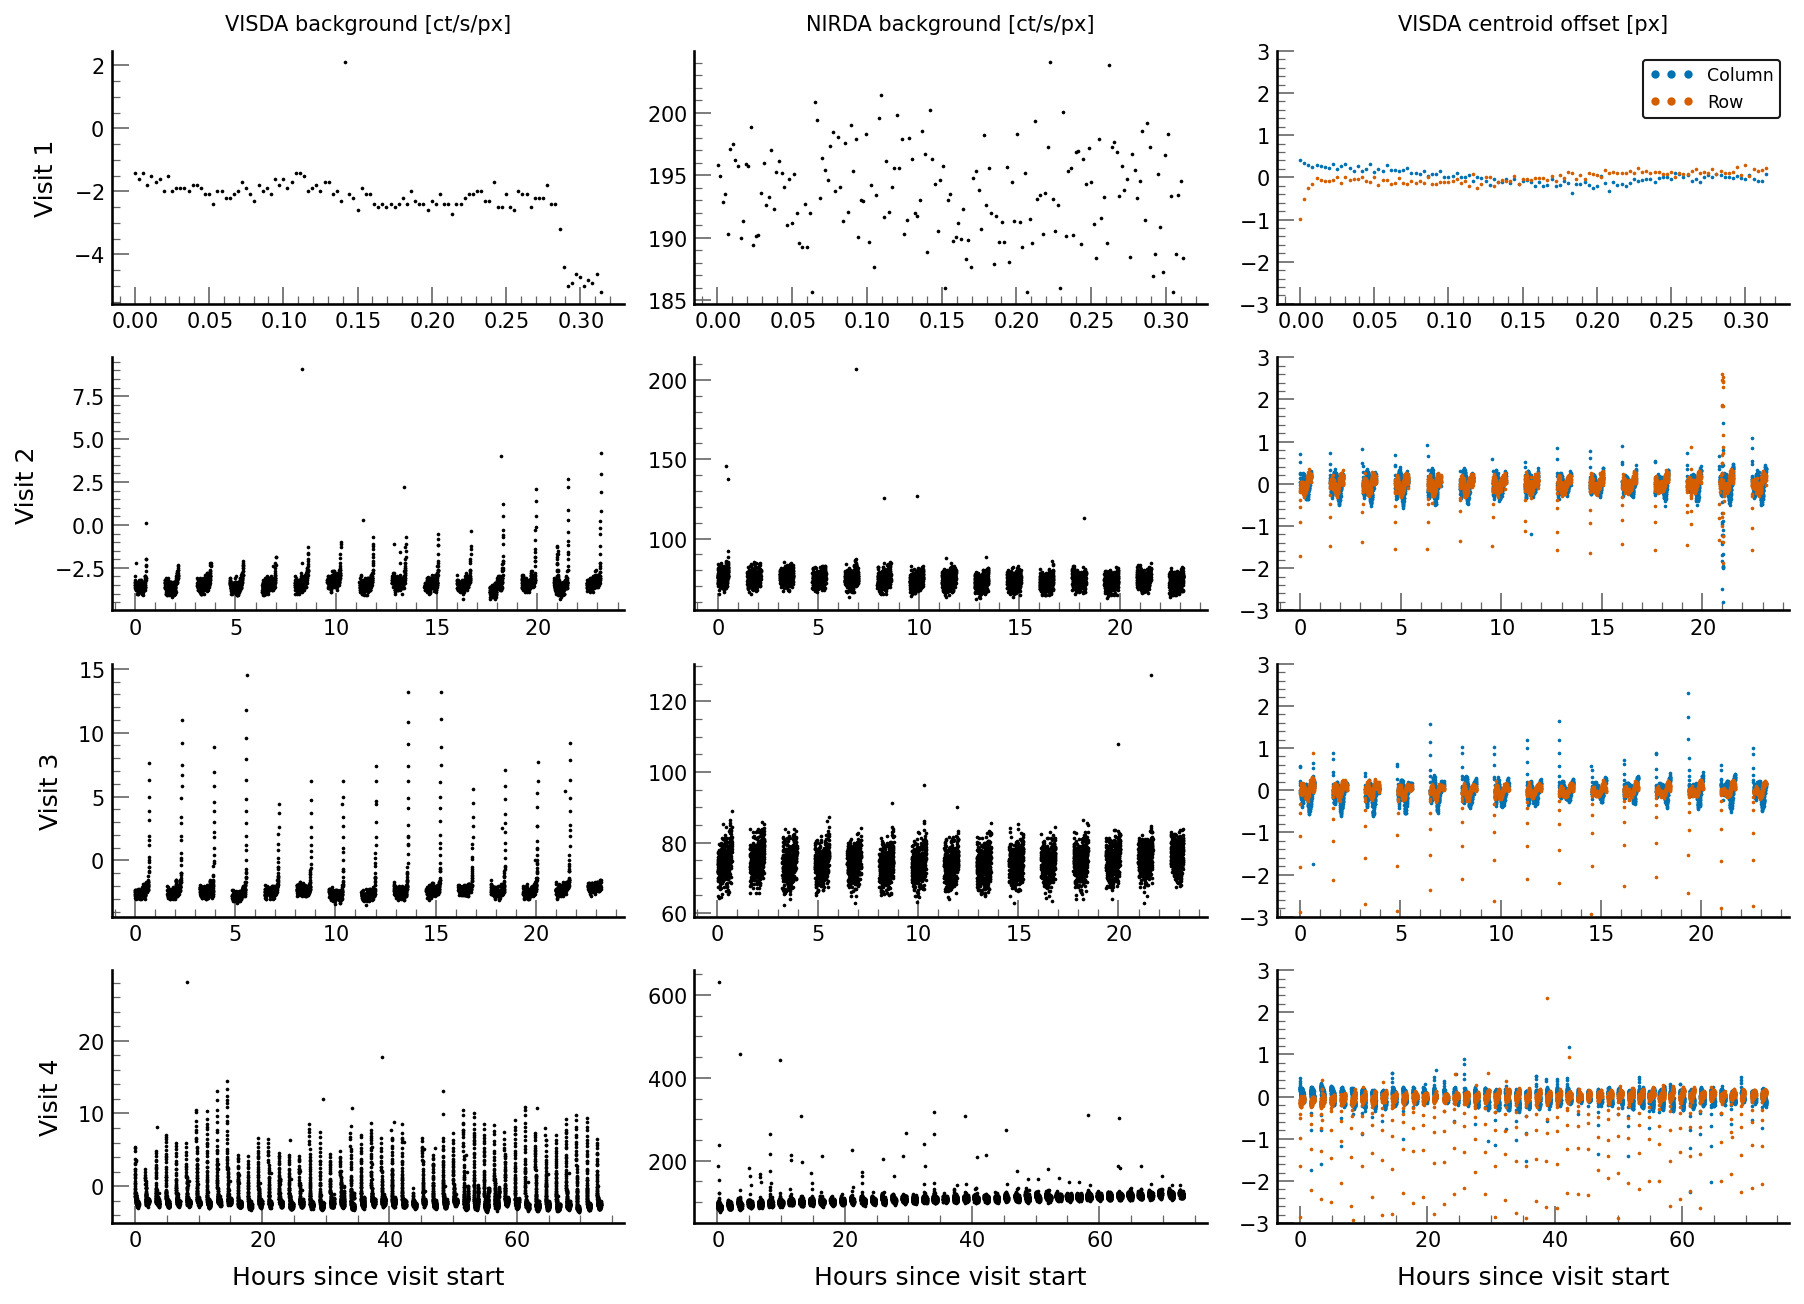

In [8]:
fig, axes = plt.subplots(len(visits), 3, figsize=(12, 2.2 * len(visits)),
                         squeeze=False)
for row_axes, visit in zip(axes, visits):
    vis = visda.query("visit == @visit")
    nir = nirda.query("visit == @visit")
    vis_hours = (vis["bjd"] - vis["bjd"].min()) * 24
    nir_hours = (nir["bjd"] - vis["bjd"].min()) * 24
    row_axes[0].plot(vis_hours, vis["background"], ".", color="k",
                     markersize=1.5)
    row_axes[1].plot(nir_hours, nir["background"], ".", color="k",
                     markersize=1.5)
    row_axes[2].plot(vis_hours, vis["column"] - vis["column"].median(), ".",
                     color="#0072B2", markersize=1.5, label="Column")
    row_axes[2].plot(vis_hours, vis["row"] - vis["row"].median(), ".",
                     color="#D55E00", markersize=1.5, label="Row")
    row_axes[0].set_ylabel(f"Visit {visit}")
    row_axes[2].set_ylim(-3, 3)
for ax, title in zip(axes[0], ["VISDA background [ct/s/px]",
                               "NIRDA background [ct/s/px]",
                               "VISDA centroid offset [px]"]):
    ax.set_title(title, fontsize="medium")
axes[0, 2].legend(loc="upper right", fontsize="small", markerscale=4)
for ax in axes[-1]:
    ax.set_xlabel("Hours since visit start")
plt.show()

## Transit

All visits folded on the predicted mid-transit times. The *box depth* compares the mean flux in the middle half of the transit with the mean out of transit; it ignores limb darkening and the transit's shape, so it is a quick look rather than a measurement (a transit model fit is needed for that). Its uncertainty assumes white noise.

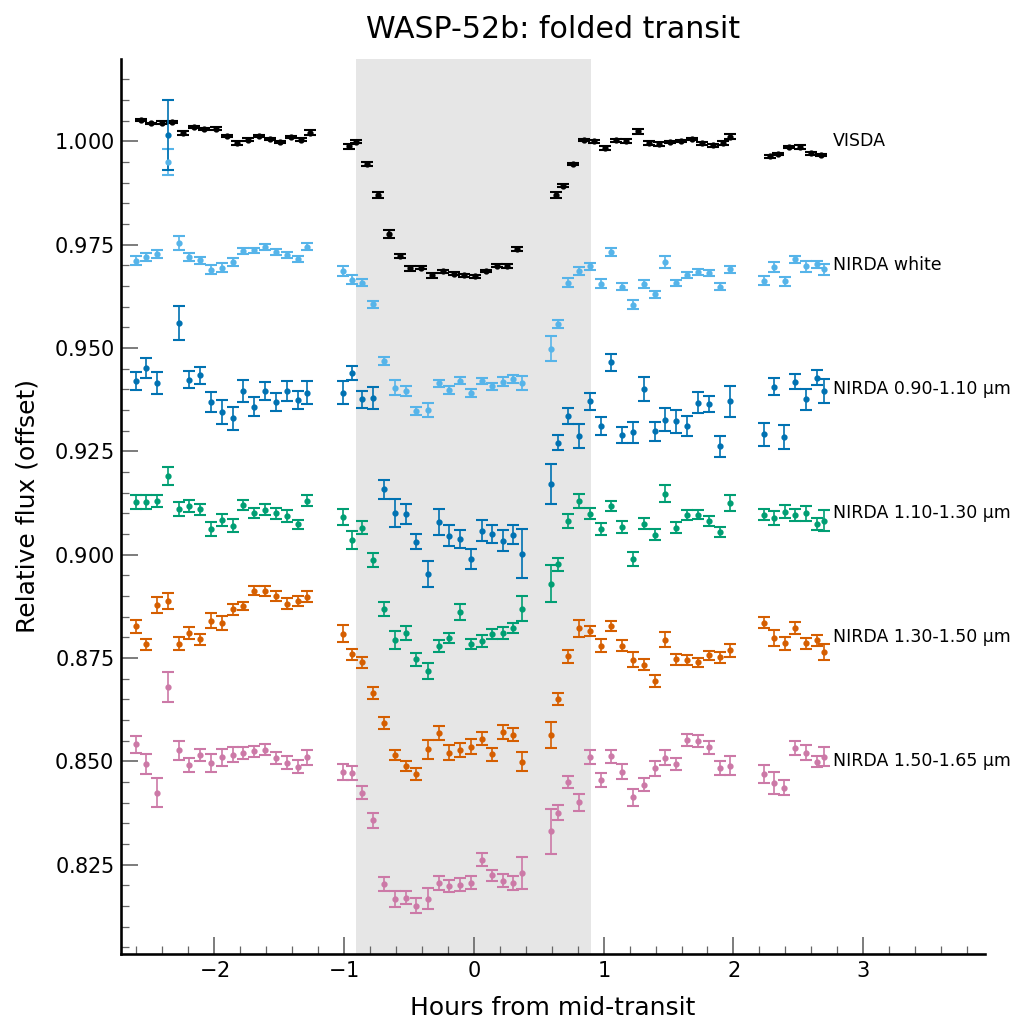

In [9]:
def folded(table, flux_column, keep_column):
    part = table[table[keep_column]]
    hours = (part["bjd"].values - nearest_transit(part["bjd"].values)) * 24
    return hours, part[flux_column].values


def box_depth(hours, flux):
    duration = EPHEMERIS["duration_hours"]
    core = np.abs(hours) < duration / 4
    outside = np.abs(hours) > duration / 2 + TRANSIT_MARGIN_MINUTES / 60
    if core.sum() < 10:
        return np.nan, np.nan
    baseline = flux[outside].mean()
    depth = 1 - flux[core].mean() / baseline
    error = np.hypot(flux[core].std() / np.sqrt(core.sum()),
                     flux[outside].std() / np.sqrt(outside.sum()))
    return depth, error


series = [("VISDA", visda, "detrended", "keep"),
          ("NIRDA white", nirda, "detrended", "keep")]
series += [(f"NIRDA {c[5:]} µm", nirda, c + "_detrended", c + "_keep")
           for c in channel_columns]
window = EPHEMERIS["duration_hours"] * 1.5 if EPHEMERIS else 0

if EPHEMERIS is not None:
    colors = ["k", "#56B4E9", "#0072B2", "#009E73", "#D55E00", "#CC79A7"]
    fig, ax = plt.subplots(figsize=(7, 7))
    depths = []
    for offset, (label, table, flux_column, keep_column) in enumerate(series):
        hours, flux = folded(table, flux_column, keep_column)
        close = np.abs(hours) < window
        x, y, error = binned(hours[close], flux[close], BIN_MINUTES / 60)
        ax.errorbar(x, y - 0.03 * offset, error, fmt=".",
                    color=colors[offset % len(colors)], markersize=4)
        ax.text(window * 1.02, 1 - 0.03 * offset, label, va="center",
                fontsize="small")
        depths.append((label, *box_depth(hours, flux)))
    ax.axvspan(-EPHEMERIS["duration_hours"] / 2,
               EPHEMERIS["duration_hours"] / 2, color="0.9", lw=0)
    ax.set(xlim=(-window, window * 1.45), xlabel="Hours from mid-transit",
           ylabel="Relative flux (offset)",
           title=f"{target_name}: folded transit")
    plt.show()

                    box depth [ppm]  error [ppm]
light curve                                     
VISDA                         31173          138
NIRDA white                   29693          330
NIRDA 0.90-1.10 µm            36787          832
NIRDA 1.10-1.30 µm            30122          496
NIRDA 1.30-1.50 µm            26243          566
NIRDA 1.50-1.65 µm            29101          551


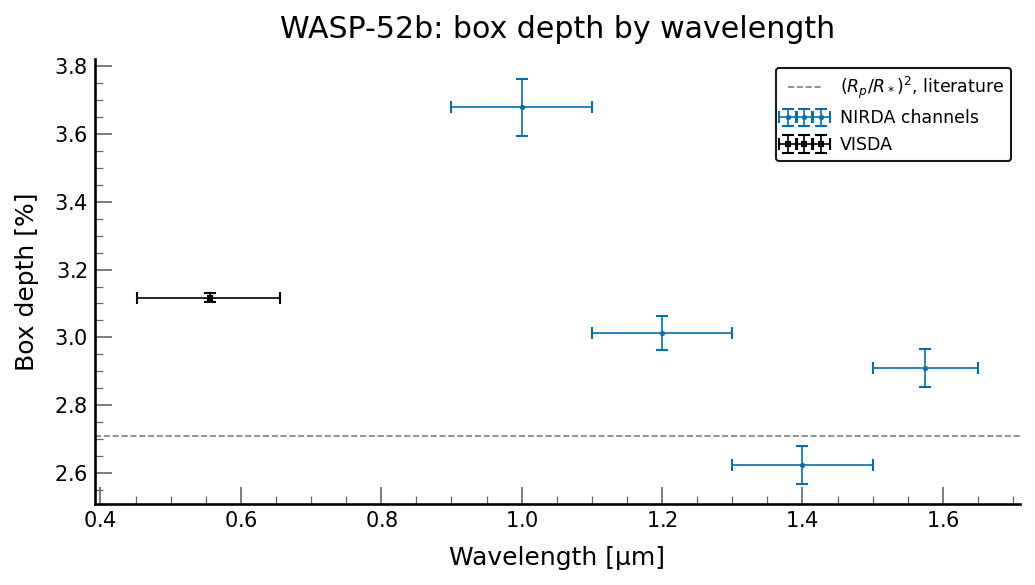

In [10]:
if EPHEMERIS is not None:
    # VISDA's effective wavelength and 16-84% range, from its sensitivity.
    grid = np.linspace(0.3, 1.1, 801) * u.micron
    weight = np.nan_to_num(
        pf.VISDAReference.get_sensitivity(grid).value
    )
    cumulative = np.cumsum(weight) / weight.sum()
    visda_wavelength = (grid.value * weight).sum() / weight.sum()
    visda_range = grid.value[np.searchsorted(cumulative, [0.16, 0.84])]

    depth_table = pd.DataFrame(
        depths, columns=["light curve", "box depth", "error"]
    ).set_index("light curve")
    print((depth_table * 1e6).round(0).astype("Int64").rename(
        columns=lambda c: c + " [ppm]"
    ))

    fig, ax = plt.subplots(figsize=(7, 4))
    channel_depths = depth_table.iloc[2:]
    centers = np.array([np.mean(c) for c in CHANNELS])
    half_widths = np.array([np.diff(c)[0] / 2 for c in CHANNELS])
    ax.errorbar(centers, channel_depths["box depth"] * 100,
                yerr=channel_depths["error"] * 100, xerr=half_widths,
                fmt="o", color="#0072B2", label="NIRDA channels")
    ax.errorbar(visda_wavelength, depth_table.loc["VISDA", "box depth"] * 100,
                yerr=depth_table.loc["VISDA", "error"] * 100,
                xerr=[[visda_wavelength - visda_range[0]],
                      [visda_range[1] - visda_wavelength]],
                fmt="s", color="k", label="VISDA")
    ax.axhline(RP_RS**2 * 100, color="0.5", ls="--",
               label=r"$(R_p/R_*)^2$, literature")
    ax.set(xlabel="Wavelength [µm]", ylabel="Box depth [%]",
           title=f"{target_name}: box depth by wavelength")
    ax.legend(fontsize="small")
    plt.show()

## Caveats

- **Box depths are not transit depths.** Without limb darkening the middle of the transit is deeper than $(R_p/R_*)^2$ in the blue and less so in the red; fit a transit model (with the systematics above as regressors, rather than dividing them out first) for real measurements.
- **Uncertainties assume white noise.** Correlated noise (see the binning test in `01_visda_reduction.ipynb`) makes them too small.
- **Remaining outliers.** Some binned points still stand out (NIRDA in visit 4 of WASP-52, whose background also shows spikes). These simple flags miss episodes such as a warm detector; spacecraft telemetry (detector temperatures) makes better flags.
- **Level 2 caveats** from the 01 and 02 notebooks apply: the VISDA bias pattern (a per-file offset as the ROI moves), the NIRDA `BACKGROUND` (pandora-fits 0.9.0 and earlier include the subarray edge columns, which lowers NIRDA fluxes by up to a few percent and slightly increases relative depths), the NIRDA time stamps, and contamination flags from visible-light fluxes.